# Resume RAG - Final Evaluation

This notebook evaluates the resume retrieval and mandatory-requirement matching pipeline on the synthetic dataset.

**Pipeline**

1. 30 synthetic PDF resumes are parsed, chunked, embedded with `sentence-transformers/all-MiniLM-L6-v2`, and stored in ChromaDB.
2. Each of the 5 job descriptions retrieves the full resume pool and ranks a top-10 list.
3. Final scores combine semantic similarity (60%), keyword overlap (30%), and experience (10%).
4. A candidate is **qualified** only when every mandatory requirement group passes and the experience threshold is met. Candidates that fail are capped at a score of 59.

> All names, organizations, and career histories are synthetic. This dataset must not be used for real hiring decisions.


In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")

# Locate the project root whether this notebook is launched from
# notebooks/ or from the repository root.
BASE_DIR = Path.cwd().resolve()
while not (BASE_DIR / "resume_manifest.csv").exists() and BASE_DIR.parent != BASE_DIR:
    BASE_DIR = BASE_DIR.parent

OUTPUT_DIR = BASE_DIR / "outputs"
MANIFEST_PATH = BASE_DIR / "resume_manifest.csv"

manifest = pd.read_csv(MANIFEST_PATH)
result_files = sorted(OUTPUT_DIR.glob("job_*-results.json"))

assert len(result_files) == 5, f"Expected 5 job result files, found {len(result_files)}"

print("Project root:", BASE_DIR)
print("Resumes in manifest:", len(manifest))
print("Job result files:", len(result_files))
print("\nResume categories:")
print(manifest["category"].value_counts().to_string())

print("\nResult files:")
for file in result_files:
    print("-", file.name)


Project root: C:\Resume-RAG
Resumes in manifest: 30
Job result files: 5

Resume categories:
category
Software Engineering      6
Data Science              6
Mechanical Engineering    6
Human Resources           6
Other Technical           6

Result files:
- job_001_python_backend_engineer-results.json
- job_002_machine_learning_engineer-results.json
- job_003_production_engineer-results.json
- job_004_talent_acquisition_specialist-results.json
- job_005_cybersecurity_analyst-results.json


In [2]:
job_category_map = {
    "job_001_python_backend_engineer": "Software Engineering",
    "job_002_machine_learning_engineer": "Data Science",
    "job_003_production_engineer": "Mechanical Engineering",
    "job_004_talent_acquisition_specialist": "Human Resources",
    "job_005_cybersecurity_analyst": "Other Technical",
}

evaluation_rows = []
qualified_rows = []
candidate_rows = []
diagnostic_rows = []

for file in result_files:
    with open(file, "r", encoding="utf-8") as handle:
        data = json.load(handle)

    job = file.stem.replace("-results", "")
    expected_category = job_category_map[job]
    top_matches = data.get("top_matches", [])[:10]

    relevant_count = 0
    qualified_count = 0

    for candidate in top_matches:
        name = candidate["candidate_name"]
        must_have = candidate.get("must_have_check", {})
        passed = bool(must_have.get("passed", False))
        missing = must_have.get("missing_requirements", [])
        evidence = must_have.get("matched_required_skills", [])

        metadata = manifest.loc[manifest["candidate_name"] == name]
        category = metadata.iloc[0]["category"] if not metadata.empty else "Unknown"

        if category == expected_category:
            relevant_count += 1

        if passed:
            qualified_count += 1
            qualified_rows.append({
                "Job": job,
                "Candidate Name": name,
                "Match Score": candidate["match_score"],
                "Experience (years)": candidate["experience_years"],
                "Matched Evidence": ", ".join(evidence) or "None",
            })

        candidate_rows.append({
            "Job": job,
            "Candidate Name": name,
            "Resume Category": category,
            "Match Score": candidate["match_score"],
            "Experience (years)": candidate["experience_years"],
            "Qualified": passed,
            "Missing Requirements": "; ".join(missing) if missing else "None",
            "Matched Evidence": ", ".join(evidence) or "None",
        })

    total_relevant = int((manifest["category"] == expected_category).sum())
    evaluated = len(top_matches)

    evaluation_rows.append({
        "Job": job,
        "Expected Category": expected_category,
        "Relevant in Top 10": relevant_count,
        "Total Relevant": total_relevant,
        "Precision@10": round(relevant_count / evaluated, 3) if evaluated else 0.0,
        "Recall@10": round(relevant_count / total_relevant, 3) if total_relevant else 0.0,
        "Retrieval Accuracy (%)": round(relevant_count / evaluated * 100, 2) if evaluated else 0.0,
        "Qualified Candidates": qualified_count,
        "Must-have Pass Rate (%)": round(qualified_count / evaluated * 100, 2) if evaluated else 0.0,
        "Required Experience": data.get("detected_required_experience"),
        "Latency (seconds)": data.get("latency_seconds"),
    })

    diagnostic_rows.append({
        "Job": job,
        "Retrieved": data.get("retrieved_candidates", 0),
        "Evaluated in Top 10": evaluated,
        "Unique Names": len({c["candidate_name"] for c in top_matches}),
        "Qualified": qualified_count,
        "Rejected": evaluated - qualified_count,
    })

evaluation_df = pd.DataFrame(evaluation_rows)
qualified_df = pd.DataFrame(qualified_rows)
candidate_df = pd.DataFrame(candidate_rows)
diagnostics_df = pd.DataFrame(diagnostic_rows)

evaluation_df


,Job,Expected Category,Relevant in Top 10,Total Relevant,Precision@10,Recall@10,Retrieval Accuracy (%),Qualified Candidates,Must-have Pass Rate (%),Required Experience,Latency (seconds)
0,job_001_python_backend_engineer,Software Engineering,6,6,0.6,1.000,60.0,0,0.0,5,0.3486
1,job_002_machine_learning_engineer,Data Science,4,6,0.4,0.667,40.0,1,10.0,3,0.2836
2,job_003_production_engineer,Mechanical Engineering,5,6,0.5,0.833,50.0,1,10.0,3,0.2447
3,job_004_talent_acquisition_specialist,Human Resources,4,6,0.4,0.667,40.0,0,0.0,3,0.2455
4,job_005_cybersecurity_analyst,Other Technical,3,6,0.3,0.500,30.0,0,0.0,3,0.2463


In [3]:
display(evaluation_df)

total_qualified = int(evaluation_df["Qualified Candidates"].sum())
avg_precision = evaluation_df["Precision@10"].mean()
avg_recall = evaluation_df["Recall@10"].mean()
avg_latency = evaluation_df["Latency (seconds)"].mean()

names = ", ".join(qualified_df["Candidate Name"].tolist()) if not qualified_df.empty else "None"

summary = f"""
### Evaluation snapshot

- **Qualified candidates:** {total_qualified} across the five jobs ({names})
- **Average Precision@10:** {avg_precision:.3f}
- **Average Recall@10:** {avg_recall:.3f}
- **Average retrieval accuracy:** {evaluation_df['Retrieval Accuracy (%)'].mean():.2f}%
- **Average matching latency:** {avg_latency:.4f} seconds
- **Qualification rule:** every mandatory group must pass; experience thresholds are enforced independently.
"""
display(Markdown(summary))


,Job,Expected Category,Relevant in Top 10,Total Relevant,Precision@10,Recall@10,Retrieval Accuracy (%),Qualified Candidates,Must-have Pass Rate (%),Required Experience,Latency (seconds)
0,job_001_python_backend_engineer,Software Engineering,6,6,0.6,1.000,60.0,0,0.0,5,0.3486
1,job_002_machine_learning_engineer,Data Science,4,6,0.4,0.667,40.0,1,10.0,3,0.2836
2,job_003_production_engineer,Mechanical Engineering,5,6,0.5,0.833,50.0,1,10.0,3,0.2447
3,job_004_talent_acquisition_specialist,Human Resources,4,6,0.4,0.667,40.0,0,0.0,3,0.2455
4,job_005_cybersecurity_analyst,Other Technical,3,6,0.3,0.500,30.0,0,0.0,3,0.2463



### Evaluation snapshot

- **Qualified candidates:** 2 across the five jobs (Sana Khan, Kavya Menon)
- **Average Precision@10:** 0.440
- **Average Recall@10:** 0.733
- **Average retrieval accuracy:** 44.00%
- **Average matching latency:** 0.2737 seconds
- **Qualification rule:** every mandatory group must pass; experience thresholds are enforced independently.


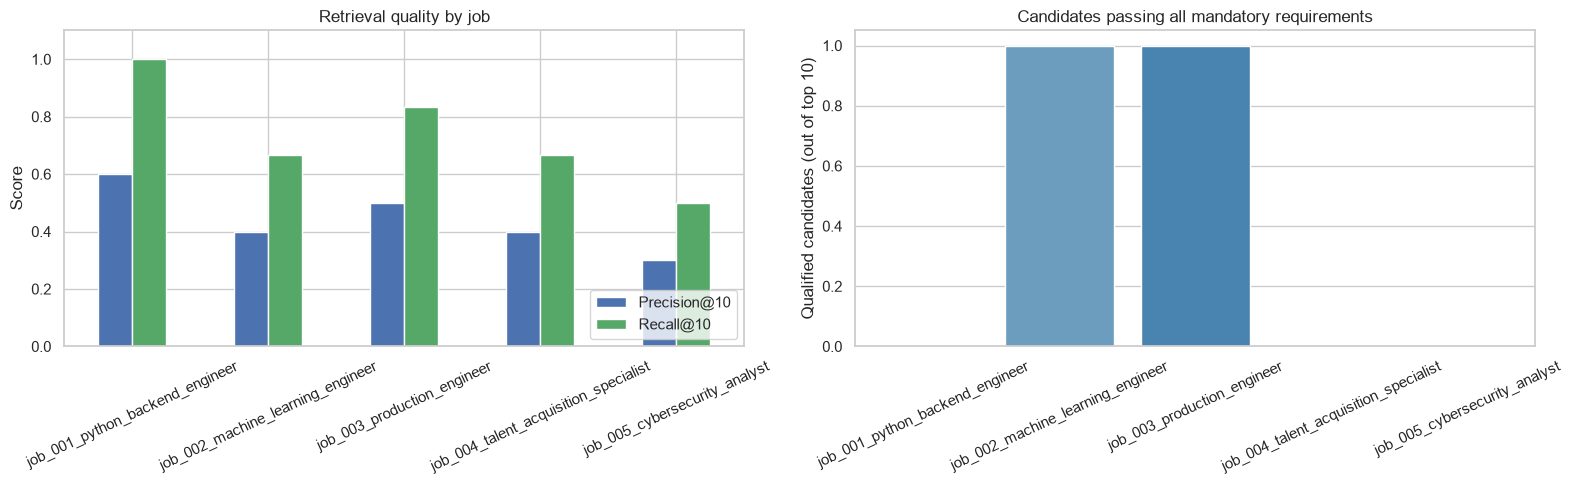

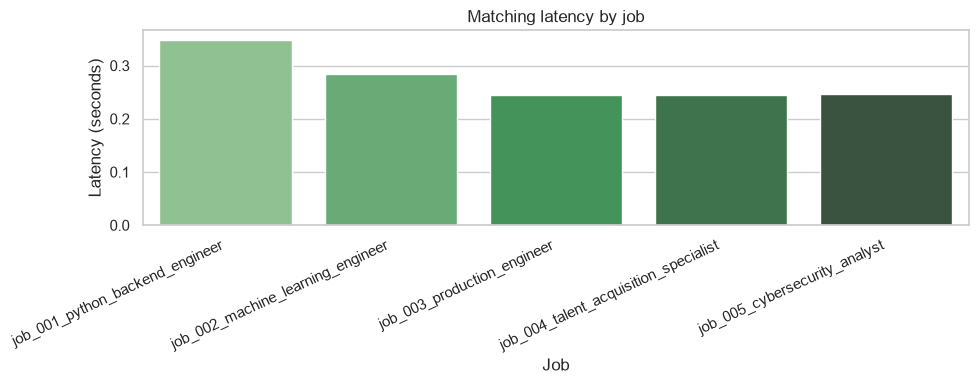

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

evaluation_df.set_index("Job")[["Precision@10", "Recall@10"]].plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#55A868"]
)
axes[0].set_title("Retrieval quality by job")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.1)
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(loc="lower right")

sns.barplot(
    data=evaluation_df,
    x="Job",
    y="Qualified Candidates",
    hue="Job",
    palette="Blues_d",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Candidates passing all mandatory requirements")
axes[1].set_ylabel("Qualified candidates (out of top 10)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.barplot(
    data=evaluation_df,
    x="Job",
    y="Latency (seconds)",
    hue="Job",
    palette="Greens_d",
    legend=False,
)
plt.title("Matching latency by job")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [5]:
display(Markdown("### Qualified candidates"))
if qualified_df.empty:
    print("No candidate passed all mandatory requirements.")
else:
    display(qualified_df.reset_index(drop=True))

display(Markdown("### Pipeline diagnostics"))
display(diagnostics_df)


### Qualified candidates

,Job,Candidate Name,Match Score,Experience (years),Matched Evidence
0,job_002_machine_learning_engineer,Sana Khan,79.91,5.0,"deployed nlp classification models, machine le..."
1,job_003_production_engineer,Kavya Menon,71.78,5.0,"b.e., kaizen, lean manufacturing, manufacturin..."


### Pipeline diagnostics

,Job,Retrieved,Evaluated in Top 10,Unique Names,Qualified,Rejected
0,job_001_python_backend_engineer,30,10,10,0,10
1,job_002_machine_learning_engineer,30,10,10,1,9
2,job_003_production_engineer,30,10,10,1,9
3,job_004_talent_acquisition_specialist,30,10,10,0,10
4,job_005_cybersecurity_analyst,30,10,10,0,10


In [6]:
display(Markdown("### Top five candidates per job and their missing requirements"))

top_five = candidate_df.groupby("Job", sort=False, group_keys=False).head(5)

display(
    top_five[[
        "Job",
        "Candidate Name",
        "Match Score",
        "Experience (years)",
        "Qualified",
        "Missing Requirements",
        "Matched Evidence",
    ]].reset_index(drop=True)
)


### Top five candidates per job and their missing requirements

,Job,Candidate Name,Match Score,Experience (years),Qualified,Missing Requirements,Matched Evidence
0,job_001_python_backend_engineer,Aarav Mehta,59.00,3.0,False,Production deployment; 5+ years of experience ...,"built rest apis, django, docker, fastapi, post..."
1,job_001_python_backend_engineer,Diya Sharma,59.00,5.0,False,REST API development; Production deployment,"django, docker, flask, postgresql, python"
2,job_001_python_backend_engineer,Rohan Gupta,58.23,6.0,False,REST API development; Docker,"deployment, fastapi, postgresql, python"
3,job_001_python_backend_engineer,Ishita Rao,56.77,4.0,False,Production deployment; 5+ years of experience ...,"django, docker, mysql, python, rest api, rest ..."
4,job_001_python_backend_engineer,Kabir Nair,47.95,1.0,False,REST API development; Docker; Production deplo...,"flask, python, sql"
5,job_002_machine_learning_engineer,Sana Khan,79.91,5.0,True,None,"deployed nlp classification models, machine le..."
6,job_002_machine_learning_engineer,Aarav Mehta,56.09,3.0,False,Machine learning; Deep learning framework (PyT...,python
7,job_002_machine_learning_engineer,Diya Sharma,53.59,5.0,False,Machine learning; Deep learning framework (PyT...,python
8,job_002_machine_learning_engineer,Rohan Gupta,49.96,6.0,False,Machine learning; Deep learning framework (PyT...,python
9,job_002_machine_learning_engineer,Neil Thomas,48.22,8.0,False,Deep learning framework (PyTorch or TensorFlow...,"machine learning, python"


In [7]:
def load_job(job):
    path = OUTPUT_DIR / f"{job}-results.json"
    with open(path, "r", encoding="utf-8") as handle:
        return json.load(handle)


def get_candidate(job, name):
    for candidate in load_job(job)["top_matches"]:
        if candidate["candidate_name"] == name:
            return candidate
    raise AssertionError(f"{name} not found in {job}")


def requirement(candidate, label):
    for item in candidate["must_have_check"]["requirement_details"]:
        if item["requirement"] == label:
            return item
    raise AssertionError(f"Requirement not found: {label}")


# 1. Plural wording: "REST API" must match "REST APIs".
aarav = get_candidate("job_001_python_backend_engineer", "Aarav Mehta")
assert requirement(aarav, "REST API development")["passed"]
assert not aarav["must_have_check"]["passed"]
assert "Production deployment" in aarav["must_have_check"]["missing_requirements"]
assert "5+ years of experience required" in aarav["must_have_check"]["missing_requirements"]

# 2. Diya has enough experience and frameworks but still lacks REST API and deployment evidence.
diya = get_candidate("job_001_python_backend_engineer", "Diya Sharma")
assert not diya["must_have_check"]["passed"]
assert {"REST API development", "Production deployment"}.issubset(
    set(diya["must_have_check"]["missing_requirements"])
)

# 3. Deployment phrasing: Sana must qualify with explicit deployment/monitoring evidence.
sana = get_candidate("job_002_machine_learning_engineer", "Sana Khan")
assert sana["must_have_check"]["passed"]
sana_evidence = set(sana["must_have_check"]["matched_required_skills"])
assert {"deployed nlp classification models", "monitored production drift"}.issubset(sana_evidence)

# 4. Sourcing synonym must match, but the stakeholder requirement stays strict.
riya = get_candidate("job_004_talent_acquisition_specialist", "Riya Kapoor")
assert requirement(riya, "Candidate sourcing")["passed"]
assert not riya["must_have_check"]["passed"]
assert riya["must_have_check"]["missing_requirements"] == ["Stakeholder communication"]

# 5. Cybersecurity candidate must still fail only on missing networking evidence.
pranav = get_candidate("job_005_cybersecurity_analyst", "Pranav Kulkarni")
assert not pranav["must_have_check"]["passed"]
assert pranav["must_have_check"]["missing_requirements"] == ["Networking"]

# 6. No artificial inflation: exactly two candidates qualify overall.
assert set(qualified_df["Candidate Name"]) == {"Sana Khan", "Kavya Menon"}

print("All 6 validation checks passed.")


All 6 validation checks passed.


In [8]:
metrics_columns = [
    "Job",
    "Expected Category",
    "Relevant in Top 10",
    "Total Relevant",
    "Precision@10",
    "Recall@10",
    "Retrieval Accuracy (%)",
    "Qualified Candidates",
    "Must-have Pass Rate (%)",
    "Latency (seconds)",
]

evaluation_df[metrics_columns].to_csv(
    OUTPUT_DIR / "evaluation_metrics.csv", index=False
)
evaluation_df.to_csv(
    OUTPUT_DIR / "final_evaluation_report.csv", index=False
)
qualified_df.to_csv(
    OUTPUT_DIR / "qualified_candidates.csv", index=False
)
candidate_df.to_csv(
    OUTPUT_DIR / "missing_requirements.csv", index=False
)

print("Saved:")
for name in [
    "evaluation_metrics.csv",
    "final_evaluation_report.csv",
    "qualified_candidates.csv",
    "missing_requirements.csv",
]:
    path = OUTPUT_DIR / name
    print(f"- {path} ({path.stat().st_size:,} bytes)")

print("\nOverall averages:")
print("  Precision@10:", round(evaluation_df["Precision@10"].mean(), 3))
print("  Recall@10:   ", round(evaluation_df["Recall@10"].mean(), 3))
print("  Qualified:   ", int(evaluation_df["Qualified Candidates"].sum()))
print("  Latency (s): ", round(evaluation_df["Latency (seconds)"].mean(), 4))


Saved:
- C:\Resume-RAG\outputs\evaluation_metrics.csv (580 bytes)
- C:\Resume-RAG\outputs\final_evaluation_report.csv (610 bytes)
- C:\Resume-RAG\outputs\qualified_candidates.csv (392 bytes)
- C:\Resume-RAG\outputs\missing_requirements.csv (10,458 bytes)

Overall averages:
  Precision@10: 0.44
  Recall@10:    0.733
  Qualified:    2
  Latency (s):  0.2737


## Findings

### Correctly qualified candidates

- **Sana Khan - Machine Learning Engineer (79.91).** Explicit deployment evidence now matches: `deployed NLP classification models` and `monitored production drift`. She also has 5 years of experience, Python, PyTorch, and TensorFlow.
- **Kavya Menon - Production Engineer (71.78).** Satisfies manufacturing, Lean/Six Sigma, root-cause analysis, continuous improvement, and the engineering qualification.

### Correctly rejected near-misses

- **Aarav Mehta - Python Backend (59.0).** `Built REST APIs` is now recognized for the REST requirement, but he still fails on **production deployment** and the **5-year experience threshold** (3 years).
- **Diya Sharma - Python Backend (59.0).** Has 5 years, Django/Flask, PostgreSQL, and Docker, but no REST API or deployment evidence.
- **Riya Kapoor - Talent Acquisition (59.0).** `Sourcing` now matches the candidate-sourcing group. She remains rejected because **stakeholder communication** has no resume evidence.
- **Pranav Kulkarni - Cybersecurity (59.0).** Matches five of six groups but still has **no networking evidence**.

### Matching behavior

- Plural handling is limited to the final word of a requirement phrase, so `REST API` matches `REST APIs` without matching unrelated words.
- The ML deployment group requires a specific phrase such as `deployed ML models` or `monitored production drift`; bare `deployed` is deliberately not accepted.
- Requirement groups use **OR within a group** and **AND across groups**. Missing requirements are never awarded on semantic similarity alone.

### Retrieval quality

Category-level relevance is intentionally coarse: it measures whether a retrieved resume belongs to the expected discipline, not whether the candidate is qualified. Precision@10 and Recall@10 should therefore be read alongside the mandatory-requirement results, not as hiring accuracy.


## Reproduce the results

Run these commands from the project root:

```powershell
# 1. Build or refresh the vector database from the PDF resumes
.\.venv\Scripts\python.exe .\src\resume_rag.py

# 2. Match every job description (each run writes its own report)
Get-ChildItem .\job_descriptions\job_*.txt | ForEach-Object {
    .\.venv\Scripts\python.exe .\src\job_matcher.py $_.FullName
}

# 3. Re-execute this notebook
.\.venv\Scripts\jupyter.exe nbconvert --to notebook --execute --inplace .\notebooks\evaluation.ipynb
```

### Outputs

- `outputs/job_00X_*-results.json` - per-job ranked candidates and full requirement evidence
- `outputs/evaluation_metrics.csv` - retrieval and qualification metrics
- `outputs/final_evaluation_report.csv` - full evaluation table
- `outputs/qualified_candidates.csv` - candidates passing every mandatory requirement
- `outputs/missing_requirements.csv` - top-10 candidates with missing-requirement details

### Limitations

- The dataset is synthetic and small (30 resumes, 5 jobs).
- Matching is keyword- and phrase-based, so unseen synonyms still require explicit alternatives.
- Category labels are used as a proxy for retrieval relevance.
- A production system would add recency weighting, skill-level extraction, and human review.
